# 03 — Exploratory Data Analysis for Regression

This notebook explores the continuous next-week recorded-sales target and the predictors available at the end of the current week. It examines scale, skewness, zero demand, concentration, temporal patterns, historical demand, price, channel mix, product groups, redundancy, missingness, anomalies, and predictor drift.

All target-based analysis uses the **training partition only**. Validation and test are used only for target-free predictor-drift checks; final-test outcomes remain uninspected until the modelling design is fixed. Relationships are descriptive or predictive and are not interpreted as causal.

## 1. Load the validated article-week publication

The notebook resolves the versioned run referenced by `CURRENT.json`, rejects previews or unsafe paths, verifies the dataset checksum, and loads only the columns required for regression EDA.

In [1]:
%pip install "seaborn>=0.13,<1"

from pathlib import Path
import hashlib
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

SEED = 42
ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src/data/process_data.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the fashion-demand-ml project.")

processed_dir = ROOT / "data/processed"
pointer = json.loads((processed_dir / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed_dir / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed_dir.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json does not reference a valid complete publication.")
summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
dataset_path = run_dir / "article_week.csv.gz"
digest = hashlib.sha256()
with dataset_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if digest.hexdigest() != checksums[dataset_path.name]:
    raise ValueError("The article-week dataset changed after publication.")

lag_columns = [f"lag_{lag}_sales" for lag in range(1, 13)]
use_columns = [
    "week", "target_week", "article_id", "split", "sales",
    "mean_price", "online_share", "target_next_week_sales",
    *lag_columns, "rolling_4w_sales_mean", "rolling_4w_sales_std",
    "rolling_4w_active_weeks", "rolling_12w_sales_mean",
    "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share",
    "product_group_name", "index_group_name", "garment_group_name",
]
data = pd.read_csv(
    dataset_path, usecols=use_columns, dtype={"article_id": "string"},
    parse_dates=["week", "target_week"],
)
train = data.loc[data["split"].eq("train")].copy()
target = "target_next_week_sales"
assert set(data["split"].unique()) == {"train", "validation", "test"}
assert len(train) == summary["split_counts"]["train"]

PAPER, INK, MUTED, GRID = "#FAFBFC", "#17212B", "#667085", "#DDE3EA"
BLUE, TEAL, CORAL, GOLD, VIOLET = "#2F6BFF", "#16A085", "#E76F51", "#E9A23B", "#7357C8"
SPLIT_COLORS = {"train": "#6F4EAF", "validation": "#E17C05", "test": "#00A6D6"}
CATEGORY_PALETTE = [
    "#2F6BFF", "#00AA00", "#FF0011", "#FF00AA", "#775522",
    "#0099CC", "#884477", "#008866", "#DD7700", "#AA11DD",
    "#AA0033", "#999900", "#0055AA", "#CC7777", "#336600",
    "#CC66DD", "#993300", "#9988CC", "#FF2277", "#889955",
]
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
FONT = next(name for name in ["Arial", "Liberation Sans", "DejaVu Sans"] if name in available_fonts)
plt.rcParams.update({
    "font.family": FONT, "figure.facecolor": PAPER, "axes.facecolor": PAPER,
    "axes.edgecolor": GRID, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
})

def style_axis(ax, xlabel=None, ylabel=None):
    ax.set_xlabel(xlabel or "", fontweight="bold", color=INK)
    ax.set_ylabel(ylabel or "", fontweight="bold", color=INK)
    ax.grid(axis="y", color=GRID, linewidth=.7)
    ax.spines[["top", "right"]].set_visible(False)

def center_axis_title(ax):
    fig = ax.figure
    title = ax.title
    title.set_visible(False)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    content_box = ax.get_tightbbox(renderer)
    axes_box = ax.get_window_extent(renderer)
    title.set_visible(True)
    content_center = (content_box.x0 + content_box.x1) / 2
    title.set_x((content_center - axes_box.x0) / axes_box.width)

def center_figure_title(fig):
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    content_boxes = [
        ax.get_tightbbox(renderer) for ax in fig.axes if ax.get_visible()
    ]
    if fig._suptitle is not None and content_boxes:
        content_left = min(box.x0 for box in content_boxes)
        content_right = max(box.x1 for box in content_boxes)
        fig._suptitle.set_x(
            ((content_left + content_right) / 2 - fig.bbox.x0) / fig.bbox.width
        )

def finish_figure(fig, title, source="H&M article-week dataset"):
    fig.suptitle(title, fontsize=15, fontweight="bold", y=1.02)
    fig.text(.99, .005, f"Source: {source}", ha="right", color=MUTED, fontsize=8)
    center_figure_title(fig)

print("Run:", run_dir.name)
print("Rows loaded:", f"{len(data):,}")
print("Training rows used for target EDA:", f"{len(train):,}")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Run: 20261027T145552-5a1ac59a
Rows loaded: 1,887,139
Training rows used for target EDA: 1,326,434


## 2. Dataset and temporal overview

The split table establishes population size and calendar coverage. The time-series figure uses current-week recorded sales, which are available at prediction time; it does not reveal future test targets. Vertical boundaries show when validation and test begin.

,article_weeks,articles,weeks,first_week,last_week,recorded_current_week_sales
split,,,,,,
train,1326434,77357,62,2018-12-17,2020-02-17,18870639
validation,271215,40820,15,2020-02-24,2020-06-01,4293139
test,289490,43869,14,2020-06-08,2020-09-07,4533906


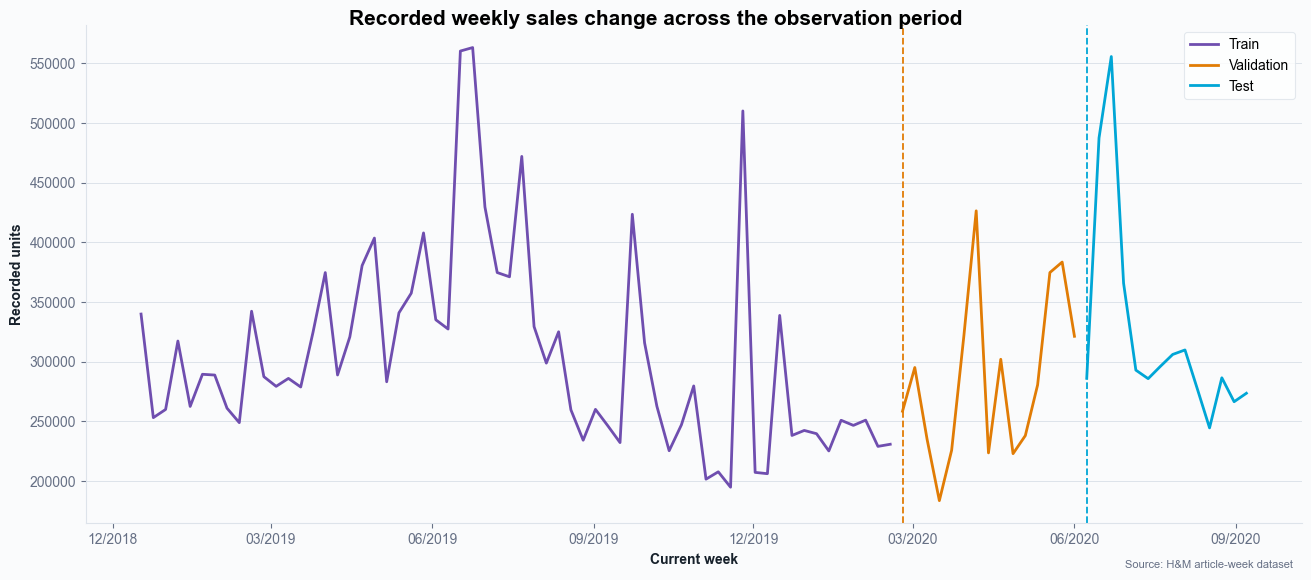

In [2]:
split_order = ["train", "validation", "test"]
split_overview = data.groupby("split").agg(
    article_weeks=("article_id", "size"),
    articles=("article_id", "nunique"),
    weeks=("week", "nunique"),
    first_week=("week", "min"),
    last_week=("week", "max"),
    recorded_current_week_sales=("sales", "sum"),
).reindex(split_order)
display(split_overview)

weekly_current = data.groupby("week", sort=True)["sales"].sum()
validation_start = data.loc[data["split"].eq("validation"), "week"].min()
test_start = data.loc[data["split"].eq("test"), "week"].min()
fig, ax = plt.subplots(figsize=(13, 5.5), layout="constrained")
split_masks = {
    "train": weekly_current.index < validation_start,
    "validation": (weekly_current.index >= validation_start) & (weekly_current.index < test_start),
    "test": weekly_current.index >= test_start,
}
for split, mask in split_masks.items():
    split_series = weekly_current.loc[mask]
    ax.plot(
        split_series.index, split_series.values, color=SPLIT_COLORS[split],
        linewidth=2, label=split.title(),
    )
ax.axvline(validation_start, color=SPLIT_COLORS["validation"], linestyle="--", linewidth=1.3)
ax.axvline(test_start, color=SPLIT_COLORS["test"], linestyle="--", linewidth=1.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
style_axis(ax, "Current week", "Recorded units")
legend = ax.legend(frameon=True, fancybox=True, facecolor="white", edgecolor=GRID)
legend.get_frame().set_linewidth(.8)
finish_figure(fig, "Recorded weekly sales change across the observation period")
plt.show()

## 3. Training-target distribution

The raw histogram is limited to the training 99th percentile so that the body of the distribution remains visible; the excluded tail is quantified in the accompanying table. The ECDF uses a declared `log1p` horizontal scale and retains every training observation, including zeros.

,value
rows,1.326434e+06
zero_target_rows,2.903510e+05
zero_target_rate,2.188959e-01
mean,1.347114e+01
median,3.000000e+00
standard_deviation,3.414135e+01
skewness,8.674725e+00
maximum,3.100000e+03


,recorded_units
0.000,0.0
0.250,1.0
0.500,3.0
0.750,11.0
0.900,33.0
0.950,60.0
0.990,159.0
0.995,218.0
1.000,3100.0


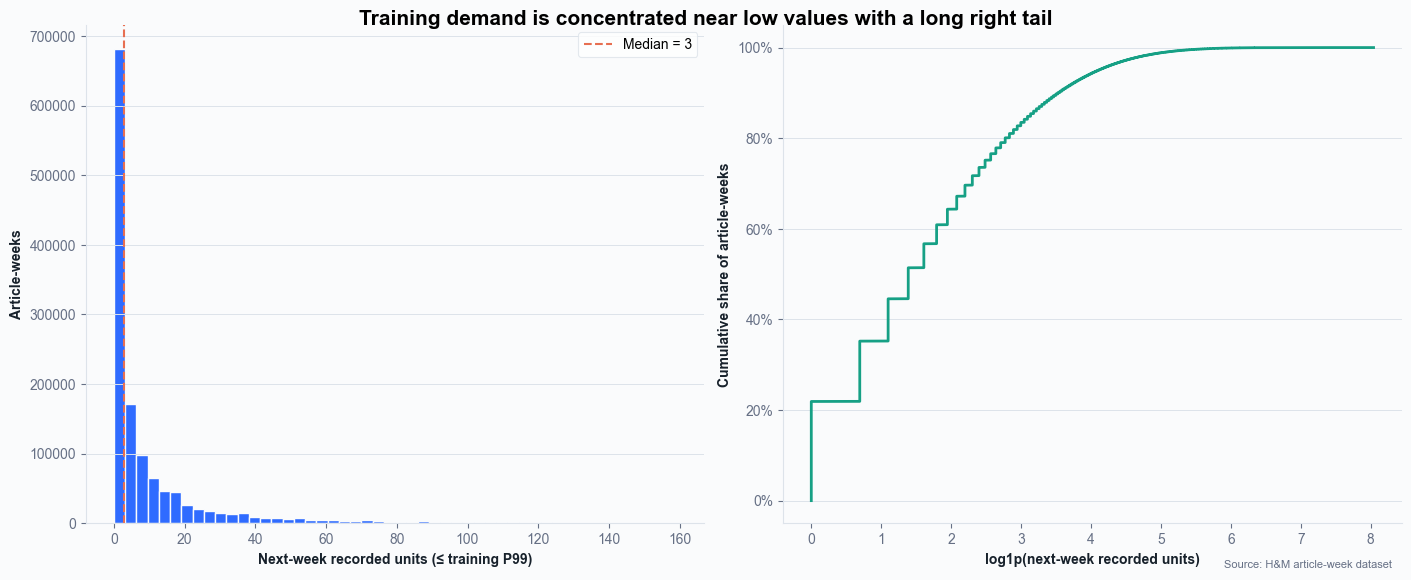

In [3]:
target_quantiles = train[target].quantile([0, .25, .5, .75, .9, .95, .99, .995, 1])
target_statistics = pd.Series({
    "rows": len(train),
    "zero_target_rows": int(train[target].eq(0).sum()),
    "zero_target_rate": train[target].eq(0).mean(),
    "mean": train[target].mean(),
    "median": train[target].median(),
    "standard_deviation": train[target].std(),
    "skewness": train[target].skew(),
    "maximum": train[target].max(),
})
display(target_statistics.to_frame("value"))
display(target_quantiles.rename("recorded_units").to_frame())

p99 = target_quantiles.loc[.99]
sorted_target = np.sort(train[target].to_numpy())
ecdf = np.arange(1, len(sorted_target) + 1) / len(sorted_target)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
axes[0].hist(train.loc[train[target].le(p99), target], bins=50, color=BLUE, edgecolor=PAPER)
axes[0].axvline(train[target].median(), color=CORAL, linestyle="--", label=f"Median = {train[target].median():.0f}")
style_axis(axes[0], "Next-week recorded units (≤ training P99)", "Article-weeks")
legend = axes[0].legend(frameon=True, fancybox=True, facecolor="white", edgecolor=GRID)
legend.get_frame().set_linewidth(.8)
axes[1].plot(np.log1p(sorted_target), ecdf, color=TEAL, linewidth=2)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
style_axis(axes[1], "log1p(next-week recorded units)", "Cumulative share of article-weeks")
finish_figure(fig, "Training demand is concentrated near low values with a long right tail")
plt.show()

## 4. Demand concentration across articles

Training targets are aggregated by article to measure how much recorded future volume is concentrated in the most active products. This is descriptive concentration, not evidence that article identity should be supplied as a numeric feature.

,value
articles_in_training,77357.000000
top_1_percent_demand_share,0.195120
top_10_percent_demand_share,0.655209
articles_required_for_80_percent,13372.000000


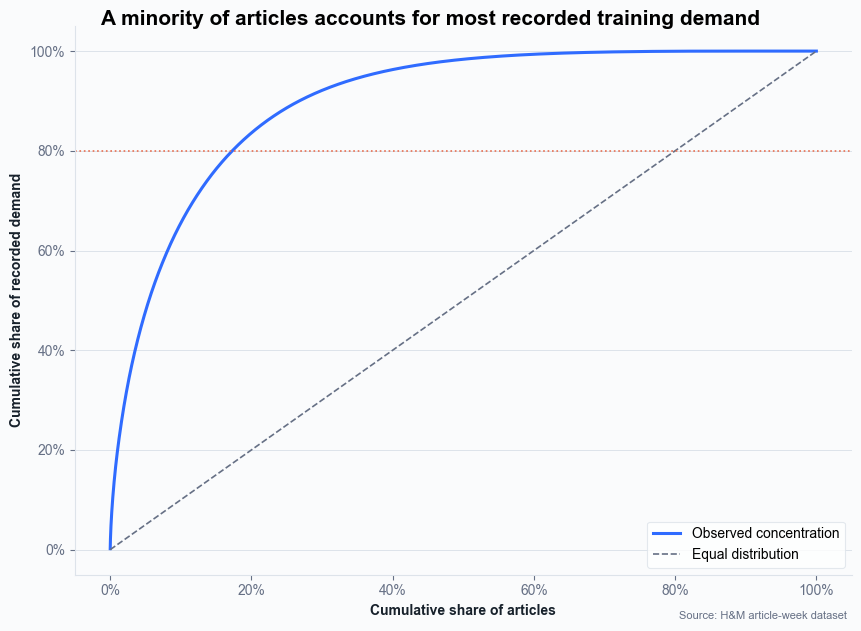

In [4]:
article_demand = train.groupby("article_id")[target].sum().sort_values(ascending=False)
article_share = np.arange(1, len(article_demand) + 1) / len(article_demand)
demand_share = article_demand.cumsum() / article_demand.sum()
def top_share(fraction):
    count = max(1, int(np.ceil(len(article_demand) * fraction)))
    return float(article_demand.iloc[:count].sum() / article_demand.sum())
concentration = pd.Series({
    "articles_in_training": len(article_demand),
    "top_1_percent_demand_share": top_share(.01),
    "top_10_percent_demand_share": top_share(.10),
    "articles_required_for_80_percent": int(np.searchsorted(demand_share.to_numpy(), .8) + 1),
})
display(concentration.to_frame("value"))

fig, ax = plt.subplots(figsize=(8.5, 6), layout="constrained")
ax.plot(article_share, demand_share.to_numpy(), color=BLUE, linewidth=2.2, label="Observed concentration")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Equal distribution")
ax.axhline(.8, color=CORAL, linestyle=":", linewidth=1.2)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
style_axis(ax, "Cumulative share of articles", "Cumulative share of recorded demand")
legend = ax.legend(frameon=True, fancybox=True, facecolor="white", edgecolor=GRID, loc="lower right")
legend.get_frame().set_linewidth(.8)
finish_figure(fig, "A minority of articles accounts for most recorded training demand")
plt.show()

## 5. Temporal behaviour of the training target

Weekly mean and median targets are shown separately from the zero-target rate to avoid a dual axis. Changes may reflect seasonality, promotions, stock, catalogue composition, or other omitted mechanisms and are not interpreted causally.

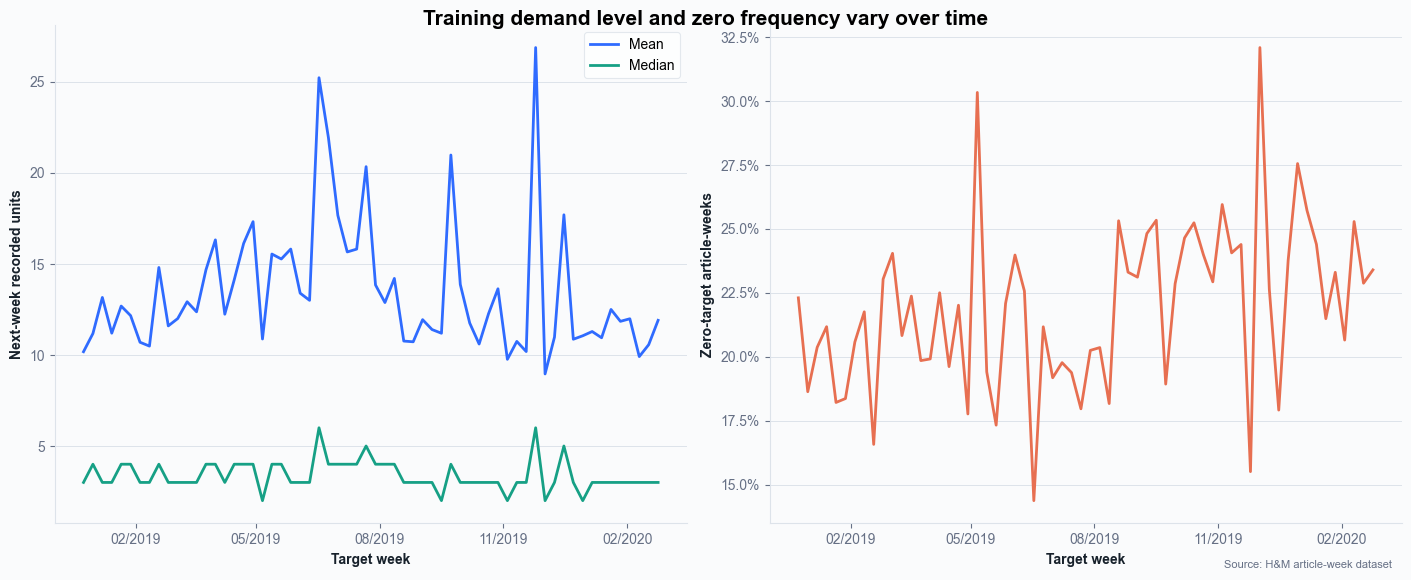

In [5]:
weekly_target = train.groupby("target_week", sort=True)[target].agg(
    mean="mean", median="median", zero_rate=lambda values: values.eq(0).mean(),
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
axes[0].plot(weekly_target.index, weekly_target["mean"], color=BLUE, linewidth=2, label="Mean")
axes[0].plot(weekly_target.index, weekly_target["median"], color=TEAL, linewidth=2, label="Median")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
style_axis(axes[0], "Target week", "Next-week recorded units")
legend = axes[0].legend(frameon=True, fancybox=True, facecolor="white", edgecolor=GRID)
legend.get_frame().set_linewidth(.8)
axes[1].plot(weekly_target.index, weekly_target["zero_rate"], color=CORAL, linewidth=2)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
style_axis(axes[1], "Target week", "Zero-target article-weeks")
finish_figure(fig, "Training demand level and zero frequency vary over time")
plt.show()

## 6. Historical demand and numeric relationships

Pearson correlation summarises linear association, while Spearman correlation captures monotonic association and is more robust to the long-tailed scale. Hexbin plots use a fixed reproducible training sample and `log1p` transformations to avoid overplotting; the correlations themselves use the complete training partition.

,pearson,spearman,absolute_spearman
sales,0.791,0.810,0.810
lag_1_sales,0.665,0.735,0.735
rolling_4w_sales_mean,0.638,0.708,0.708
rolling_4w_sales_std,0.491,0.661,0.661
lag_2_sales,0.589,0.656,0.656
rolling_12w_sales_std,0.450,0.581,0.581
rolling_12w_sales_mean,0.496,0.568,0.568
lag_4_sales,0.457,0.511,0.511
rolling_12w_active_weeks,0.018,0.260,0.260
mean_price,0.001,0.108,0.108


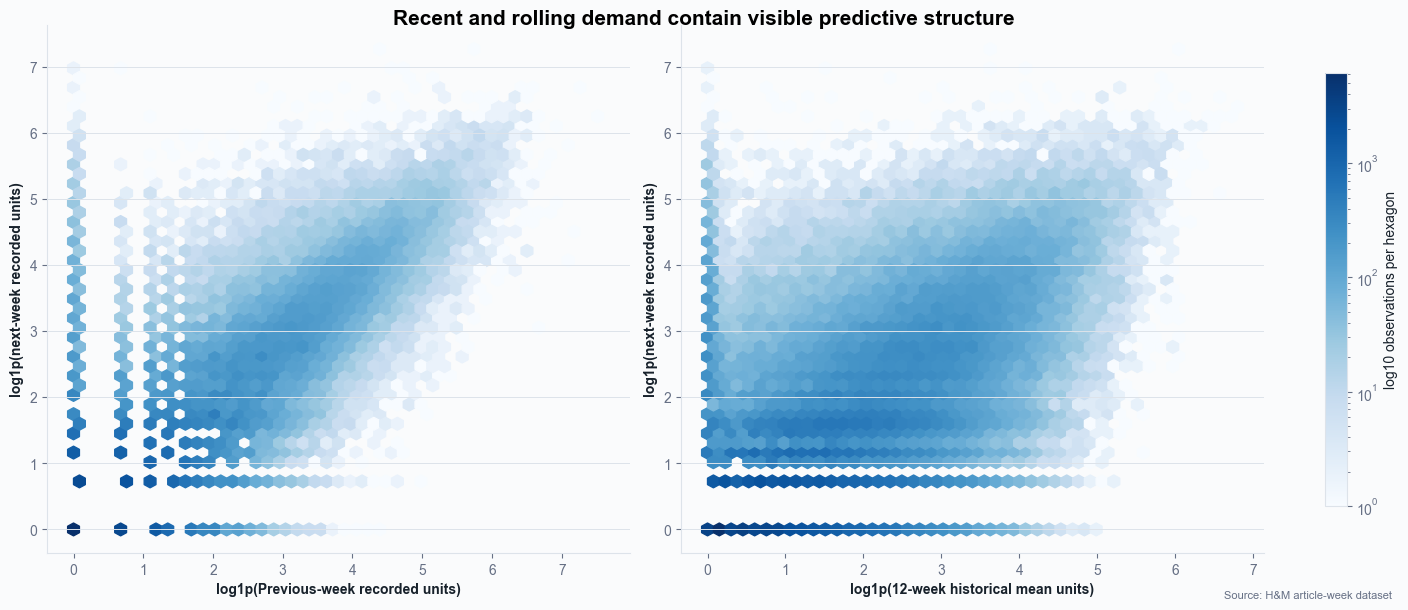

In [6]:
relationship_features = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_4_sales",
    "rolling_4w_sales_mean", "rolling_12w_sales_mean",
    "rolling_4w_sales_std", "rolling_12w_sales_std",
    "rolling_12w_active_weeks", "sales_trend_4w",
    "mean_price", "online_share", "price_change_from_4w_mean",
]
pearson = train[relationship_features + [target]].corr(method="pearson")[target].drop(target)
spearman = train[relationship_features + [target]].corr(method="spearman")[target].drop(target)
correlation_summary = pd.concat([pearson.rename("pearson"), spearman.rename("spearman")], axis=1)
correlation_summary["absolute_spearman"] = correlation_summary["spearman"].abs()
correlation_summary = correlation_summary.sort_values("absolute_spearman", ascending=False)
display(correlation_summary.round(3))

plot_sample = train.sample(n=min(180_000, len(train)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), layout="constrained")
for ax, feature, label in [
    (axes[0], "lag_1_sales", "Previous-week recorded units"),
    (axes[1], "rolling_12w_sales_mean", "12-week historical mean units"),
]:
    density = ax.hexbin(
        np.log1p(plot_sample[feature]), np.log1p(plot_sample[target]),
        gridsize=45, mincnt=1, cmap="Blues", bins="log",
    )
    style_axis(ax, f"log1p({label})", "log1p(next-week recorded units)")
fig.colorbar(density, ax=axes, label="log10 observations per hexagon", shrink=.82)
finish_figure(fig, "Recent and rolling demand contain visible predictive structure")
plt.show()

## 7. Price and product-group comparisons

The price plot uses source units because the dataset does not establish a retail currency conversion. The interval panel covers every training product group and uses six parent-family colours so related categories remain visually connected. The ridgeline panel retains the eight largest groups and is allowed its own vertical ordering; family colours remain stable across both panels. Both panels use a declared `log1p` horizontal scale, robust intervals use the complete group distributions, and ridgelines are calculated from every observation in their selected groups.

,article_weeks,mean,median,p90,zero_rate
product_group_name,,,,,
Garment Upper body,542157,13.177,3.0,33.0,0.221
Garment Lower body,261895,15.191,3.0,38.0,0.215
Garment Full body,153442,12.385,3.0,31.0,0.227
Accessories,124644,7.152,3.0,18.0,0.236
Underwear,87228,16.796,6.0,44.0,0.157
Shoes,55511,7.382,2.0,19.0,0.287
Swimwear,53021,27.485,5.0,77.0,0.168
Socks & Tights,29537,13.156,3.0,32.0,0.229
Nightwear,16555,11.934,3.0,31.0,0.239


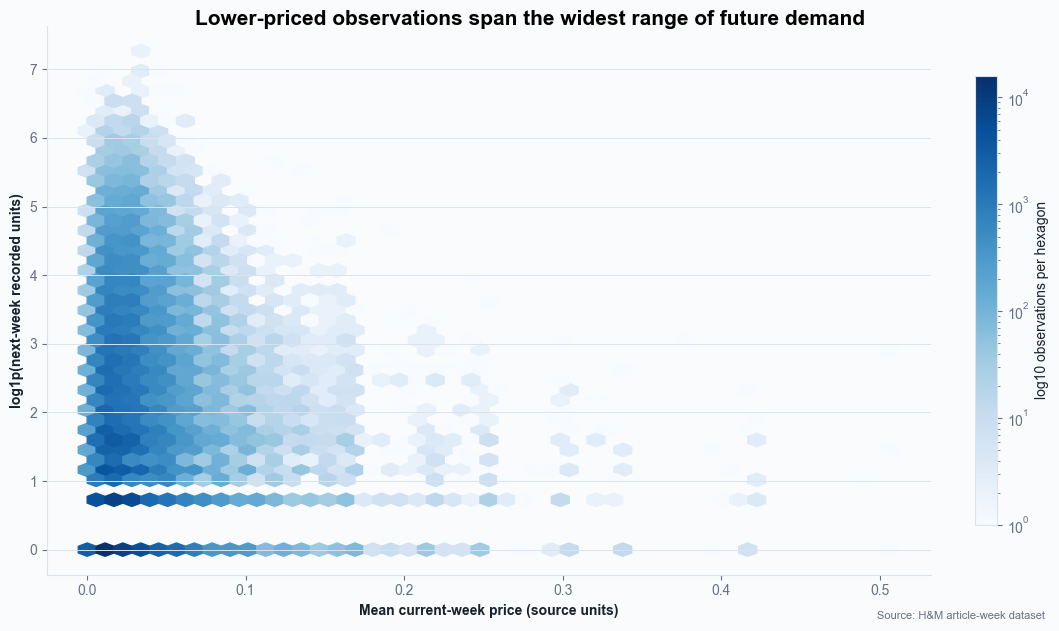

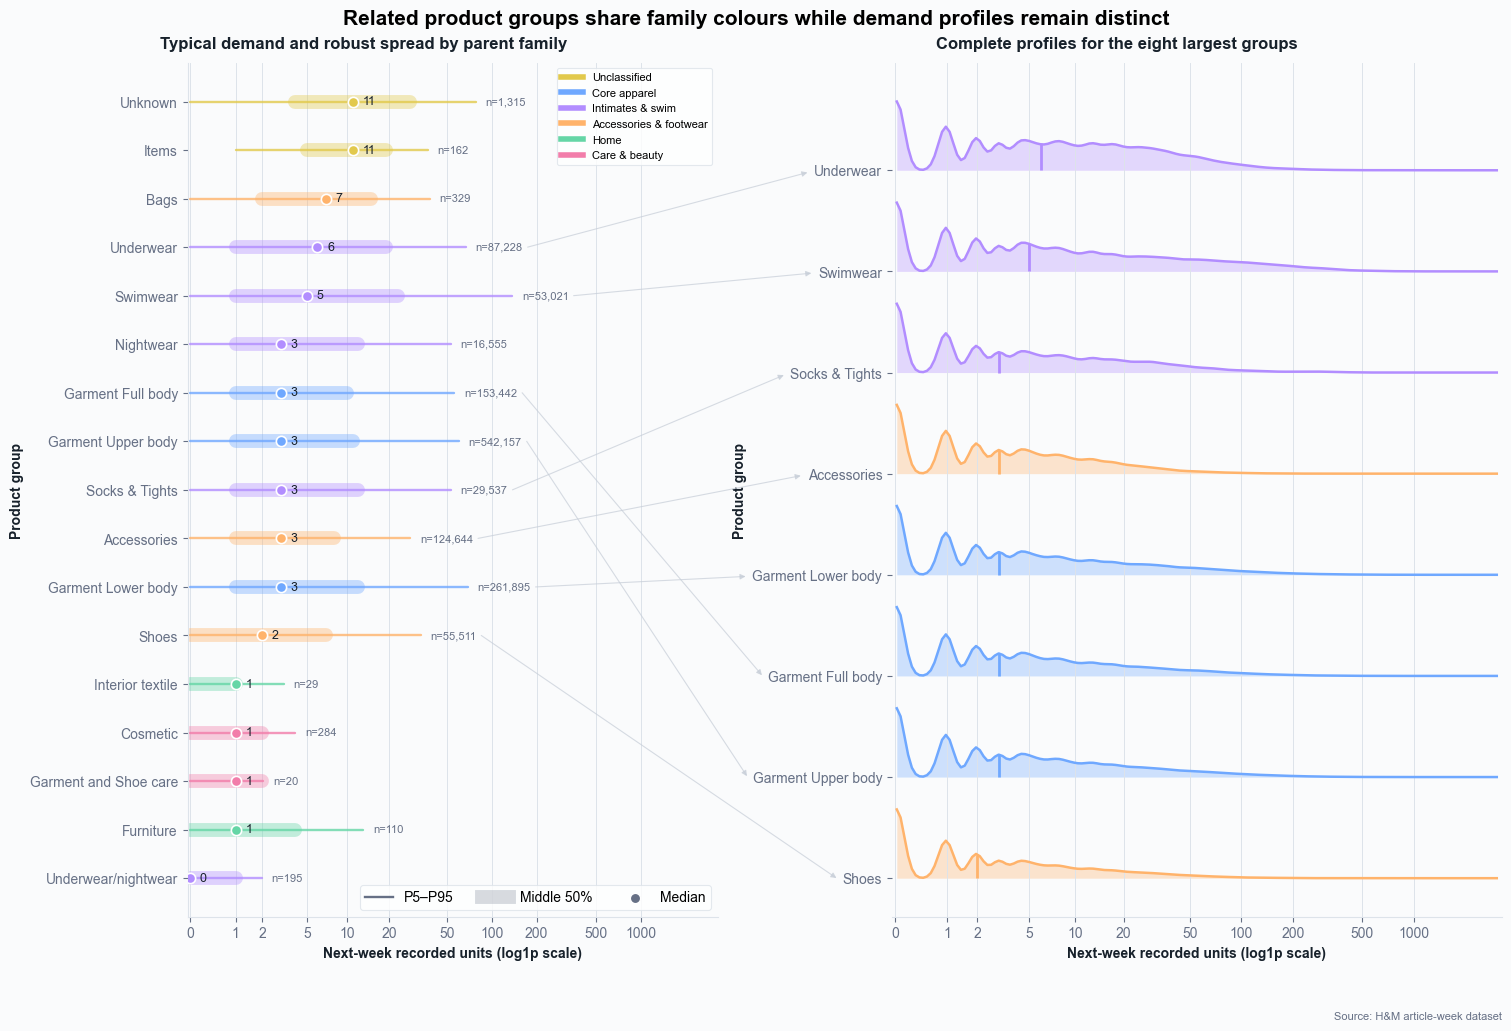

In [7]:
group_statistics = train.groupby("product_group_name")[target].agg(
    article_weeks="size", mean="mean", median="median",
    p90=lambda values: values.quantile(.90), zero_rate=lambda values: values.eq(0).mean(),
).sort_values("article_weeks", ascending=False)
display(group_statistics.round(3))

ridge_groups = group_statistics.head(8).index
category_distribution = (
    train.groupby("product_group_name")[target]
    .quantile([.05, .25, .50, .75, .95]).unstack()
    .rename(columns={.05: "p05", .25: "q1", .50: "median", .75: "q3", .95: "p95"})
    .sort_values("median")
)
price_sample = plot_sample.dropna(subset=["mean_price"])
fig, ax = plt.subplots(figsize=(10.5, 6), layout="constrained")
density = ax.hexbin(
    price_sample["mean_price"], np.log1p(price_sample[target]), gridsize=45,
    mincnt=1, cmap="Blues", bins="log",
)
style_axis(ax, "Mean current-week price (source units)", "log1p(next-week recorded units)")
fig.colorbar(density, ax=ax, label="log10 observations per hexagon", shrink=.82)
finish_figure(fig, "Lower-priced observations span the widest range of future demand")
plt.show()

group_order = category_distribution.index.tolist()
PRODUCT_GROUP_FAMILY = {
    "Unknown": "Unclassified", "Items": "Unclassified",
    "Garment Full body": "Core apparel",
    "Garment Upper body": "Core apparel",
    "Garment Lower body": "Core apparel",
    "Underwear": "Intimates & swim", "Swimwear": "Intimates & swim",
    "Nightwear": "Intimates & swim", "Socks & Tights": "Intimates & swim",
    "Underwear/nightwear": "Intimates & swim",
    "Bags": "Accessories & footwear",
    "Accessories": "Accessories & footwear",
    "Shoes": "Accessories & footwear",
    "Interior textile": "Home", "Furniture": "Home",
    "Cosmetic": "Care & beauty",
    "Garment and Shoe care": "Care & beauty",
}
FAMILY_COLORS = {
    "Unclassified": "#E2C94C",
    "Core apparel": "#6FA8FF",
    "Intimates & swim": "#B28DFF",
    "Accessories & footwear": "#FFB36B",
    "Home": "#65D6A6",
    "Care & beauty": "#F27DAA",
}
unmapped_groups = sorted(set(group_order) - PRODUCT_GROUP_FAMILY.keys())
if unmapped_groups:
    raise ValueError(f"Missing parent-family mapping for: {unmapped_groups}")
group_colors = {
    group: FAMILY_COLORS[PRODUCT_GROUP_FAMILY[group]] for group in group_order
}
ridge_order = category_distribution.loc[ridge_groups].sort_values("median").index.tolist()
group_values = {
    group: train.loc[train["product_group_name"].eq(group), target].to_numpy()
    for group in ridge_order
}
max_log_demand = max(
    max(np.log1p(values).max() for values in group_values.values()),
    np.log1p(category_distribution["p95"].max()),
)
density_edges = np.linspace(0, max_log_demand, 161)
density_x = (density_edges[:-1] + density_edges[1:]) / 2
kernel_x = np.arange(-6, 7)
density_kernel = np.exp(-.5 * (kernel_x / 2) ** 2)
density_kernel /= density_kernel.sum()

fig, axes = plt.subplots(
    1, 2, figsize=(15, 10.2), layout="constrained",
    gridspec_kw={"width_ratios": [1, 1.15]},
)
interval_ax, ridge_ax = axes
sample_size_labels = {}
for position, (group, row) in enumerate(category_distribution.iterrows()):
    color = group_colors[group]
    p05, q1, median, q3, p95 = np.log1p(
        row[["p05", "q1", "median", "q3", "p95"]].to_numpy()
    )
    interval_ax.plot([p05, p95], [position, position], color=color,
                     linewidth=1.7, alpha=.8, solid_capstyle="round")
    interval_ax.plot([q1, q3], [position, position], color=color,
                     linewidth=10, alpha=.38, solid_capstyle="round")
    interval_ax.scatter(median, position, color=color, edgecolor="white",
                        linewidth=1.2, s=55, zorder=3)
    interval_ax.annotate(
        f"{row['median']:.0f}", (median, position), xytext=(7, 0),
        textcoords="offset points", va="center", color=INK, fontsize=9,
    )
    sample_size_labels[group] = interval_ax.annotate(
        f"n={group_statistics.loc[group, 'article_weeks']:,}", (p95, position),
        xytext=(7, 0), textcoords="offset points", va="center",
        color=MUTED, fontsize=8,
    )

for position, group in enumerate(ridge_order):
    color = group_colors[group]
    median = np.log1p(category_distribution.loc[group, "median"])
    density, _ = np.histogram(np.log1p(group_values[group]), bins=density_edges, density=True)
    density = np.convolve(density, density_kernel, mode="same")
    ridge_height = .68 * density / density.max() if density.max() else density
    ridge_ax.fill_between(
        density_x, position, position + ridge_height, color=color, alpha=.32, linewidth=0,
    )
    ridge_ax.plot(density_x, position + ridge_height, color=color, linewidth=1.8)
    median_height = np.interp(median, density_x, ridge_height)
    ridge_ax.vlines(median, position, position + median_height, color=color, linewidth=2)

demand_ticks = np.array([0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
demand_ticks = demand_ticks[np.log1p(demand_ticks) <= max_log_demand + .05]
interval_ax.set_yticks(range(len(group_order)), labels=group_order)
ridge_ax.set_yticks(range(len(ridge_order)), labels=ridge_order)
for ax in axes:
    ax.set_xticks(np.log1p(demand_ticks), labels=demand_ticks)
    ax.set_xlim(-.04, max_log_demand + .04)
    style_axis(ax, "Next-week recorded units (log1p scale)", "Product group")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRID, linewidth=.7)

interval_ax.set_title("Typical demand and robust spread by parent family", fontweight="bold", color=INK, pad=10)
ridge_ax.set_title("Complete profiles for the eight largest groups", fontweight="bold", color=INK, pad=10)
ridge_ax.spines["left"].set_visible(False)
interval_ax.plot([], [], color=MUTED, linewidth=1.7, label="P5–P95")
interval_ax.plot([], [], color=MUTED, linewidth=10, alpha=.25, label="Middle 50%")
interval_ax.scatter([], [], color=MUTED, edgecolor="white", s=55, label="Median")
family_handles = [
    Line2D([0], [0], color=color, linewidth=4, label=family)
    for family, color in FAMILY_COLORS.items()
]
family_legend = interval_ax.legend(
    handles=family_handles, frameon=True, fancybox=True,
    facecolor="white", edgecolor=GRID, loc="upper right", fontsize=8,
)
family_legend.get_frame().set_linewidth(.8)
interval_ax.add_artist(family_legend)
legend = interval_ax.legend(
    frameon=True, fancybox=True, facecolor="white", edgecolor=GRID,
    loc="lower right", ncol=3,
)
legend.get_frame().set_linewidth(.8)
fig.suptitle(
    "Related product groups share family colours while demand profiles remain distinct",
    fontsize=15, fontweight="bold", x=.5,
)
ridge_ax.text(
    1, -.11, "Source: H&M article-week dataset", transform=ridge_ax.transAxes,
    ha="right", va="top", color=MUTED, fontsize=8, clip_on=False,
)
center_axis_title(interval_ax)
center_axis_title(ridge_ax)
center_figure_title(fig)
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
to_figure = fig.transFigure.inverted()
ridge_label_boxes = {
    group: label.get_window_extent(renderer)
    for group, label in zip(ridge_order, ridge_ax.get_yticklabels())
}
for group in ridge_order:
    label_box = sample_size_labels[group].get_window_extent(renderer)
    start_pixels = (label_box.x1 + 5, (label_box.y0 + label_box.y1) / 2)
    target_box = ridge_label_boxes[group]
    end_pixels = (target_box.x0 - 4, (target_box.y0 + target_box.y1) / 2)
    connector = FancyArrowPatch(
        to_figure.transform(start_pixels), to_figure.transform(end_pixels),
        transform=fig.transFigure, arrowstyle="-|>", mutation_scale=8,
        linewidth=.8, color="#C7CED8", alpha=.72,
        connectionstyle="arc3,rad=0", shrinkA=0, shrinkB=2,
        clip_on=False, zorder=2,
    )
    fig.add_artist(connector)
figure_dir = ROOT / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
plt.show()

## 8. Correlation and predictor redundancy

The triangular Spearman matrix focuses on historical numeric predictors. Strong correlation does not make a feature useless, especially for regularised or tree-based models, but it warns against interpreting individual coefficients or importance values in isolation.

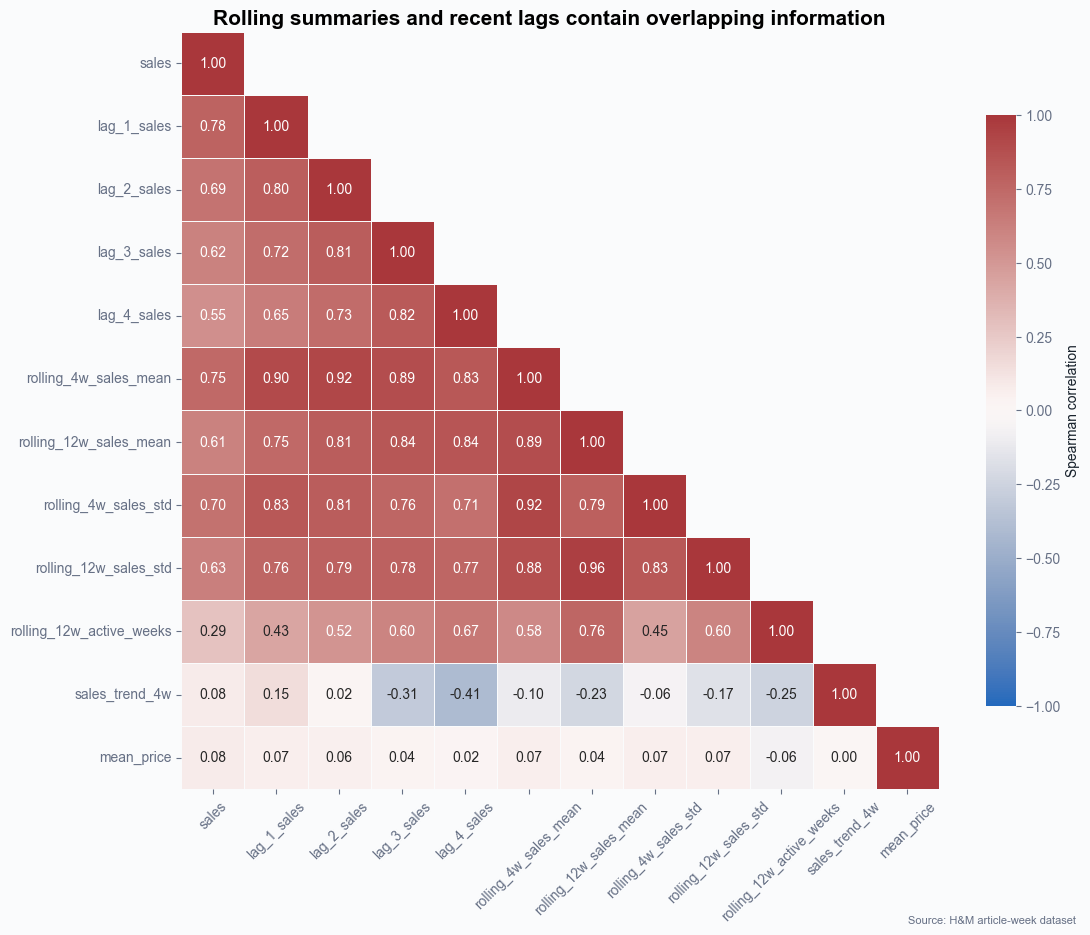

,,spearman,absolute_spearman
rolling_12w_sales_mean,rolling_12w_sales_std,0.955,0.955
rolling_4w_sales_mean,rolling_4w_sales_std,0.923,0.923
lag_2_sales,rolling_4w_sales_mean,0.917,0.917
lag_1_sales,rolling_4w_sales_mean,0.901,0.901
rolling_4w_sales_mean,rolling_12w_sales_mean,0.890,0.890
lag_3_sales,rolling_4w_sales_mean,0.889,0.889
rolling_4w_sales_mean,rolling_12w_sales_std,0.881,0.881


In [8]:
redundancy_features = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_3_sales", "lag_4_sales",
    "rolling_4w_sales_mean", "rolling_12w_sales_mean",
    "rolling_4w_sales_std", "rolling_12w_sales_std",
    "rolling_12w_active_weeks", "sales_trend_4w", "mean_price",
]
redundancy_sample = train[redundancy_features].sample(
    n=min(250_000, len(train)), random_state=SEED)
spearman_matrix = redundancy_sample.corr(method="spearman")
mask = np.triu(np.ones_like(spearman_matrix, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
sns.heatmap(
    spearman_matrix, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", square=True, linewidths=.4, linecolor=PAPER,
    cbar_kws={"label": "Spearman correlation", "shrink": .78}, ax=ax,
)
ax.set_xlabel("", fontweight="bold")
ax.set_ylabel("", fontweight="bold")
ax.tick_params(axis="x", rotation=45)
finish_figure(fig, "Rolling summaries and recent lags contain overlapping information")
plt.show()

upper = spearman_matrix.where(np.triu(np.ones(spearman_matrix.shape), k=1).astype(bool))
high_correlation_pairs = (
    upper.stack().rename("spearman").to_frame()
    .assign(absolute_spearman=lambda frame: frame["spearman"].abs())
    .query("absolute_spearman >= 0.85")
    .sort_values("absolute_spearman", ascending=False)
)
display(high_correlation_pairs.round(3))

## 9. Missingness, anomalies, and predictor drift

Missing historical price or channel summaries mean that no relevant prior sale supplied those measurements; they require fold-local imputation. Drift is measured without targets as the absolute difference from the training mean divided by the training standard deviation. It is a screening statistic, not a hypothesis test.


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


,missing_count,missing_rate
rolling_4w_mean_price,162010,8.58%
price_change_from_4w_mean,162010,8.58%
rolling_4w_online_share,162010,8.58%


,count
negative_targets_in_train,0
targets_above_training_p99,13112
nonpositive_current_sales,0
negative_prices,0
online_share_outside_0_1,0


,validation,test
rolling_4w_online_share,0.316,0.212
online_share,0.236,0.204
rolling_12w_sales_std,0.003,0.090
mean_price,0.088,0.090
rolling_12w_sales_mean,0.030,0.071
rolling_4w_sales_mean,0.011,0.066
lag_1_sales,0.034,0.046
sales,0.046,0.041
rolling_12w_active_weeks,0.135,0.022
sales_trend_4w,0.044,0.020


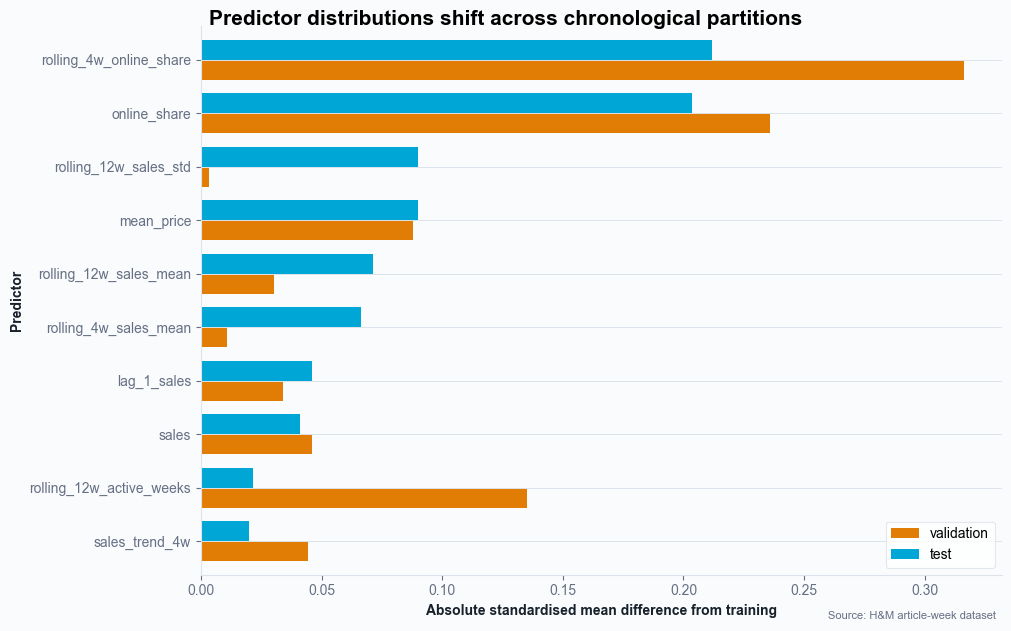

In [9]:
%pip install jinja2

quality_summary = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_rate": data.isna().mean(),
}).query("missing_count > 0").sort_values("missing_rate", ascending=False)
display(quality_summary.style.format({"missing_rate": "{:.2%}"}))

anomaly_summary = pd.Series({
    "negative_targets_in_train": int(train[target].lt(0).sum()),
    "targets_above_training_p99": int(train[target].gt(train[target].quantile(.99)).sum()),
    "nonpositive_current_sales": int(data["sales"].le(0).sum()),
    "negative_prices": int(data["mean_price"].lt(0).sum()),
    "online_share_outside_0_1": int((~data["online_share"].between(0, 1)).sum()),
})
display(anomaly_summary.to_frame("count"))

drift_features = [
    "sales", "lag_1_sales", "rolling_4w_sales_mean",
    "rolling_12w_sales_mean", "rolling_12w_sales_std",
    "rolling_12w_active_weeks", "sales_trend_4w",
    "mean_price", "online_share", "rolling_4w_online_share",
]
train_means = train[drift_features].mean()
train_stds = train[drift_features].std().replace(0, np.nan)
drift = pd.DataFrame({
    split: ((data.loc[data["split"].eq(split), drift_features].mean() - train_means) / train_stds).abs()
    for split in ["validation", "test"]
}).sort_values("test", ascending=False)
display(drift.round(3))
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
drift.sort_values("test").plot.barh(
    color=[SPLIT_COLORS[split] for split in drift.columns], width=.75, ax=ax,
)
style_axis(ax, "Absolute standardised mean difference from training", "Predictor")
legend = ax.legend(frameon=True, fancybox=True, facecolor="white", edgecolor=GRID)
legend.get_frame().set_linewidth(.8)
finish_figure(fig, "Predictor distributions shift across chronological partitions")
plt.show()

## 10. Evidence-based conclusions for regression

The following conclusions are generated from the executed training analysis so that the reported values remain consistent with the current published dataset.

In [10]:
strongest_feature = correlation_summary.index[0]
strongest_correlation = correlation_summary.iloc[0]["spearman"]
largest_drift_feature = drift["test"].idxmax()
largest_drift_value = drift.loc[largest_drift_feature, "test"]
missing_predictors = quality_summary.index.tolist()
conclusions = f"""
- The training target has a median of **{train[target].median():.0f} units**, a mean of **{train[target].mean():.2f}**, and skewness of **{train[target].skew():.2f}**. MAE should remain the primary interpretable metric, with RMSE reporting sensitivity to the long tail.
- **{train[target].eq(0).mean():.1%}** of training article-weeks have zero next-week recorded sales. Count-aware or `log1p` sensitivity analyses are justified, but all candidates must also be evaluated on the original unit scale.
- The strongest examined monotonic relationship is **{strongest_feature}** with Spearman correlation **{strongest_correlation:.3f}**. Recent-demand and rolling-history baselines are therefore essential.
- The top 10% of training articles account for **{top_share(.10):.1%}** of recorded target volume, so aggregate scores should be complemented with error analysis by demand level and product group.
- Strongly correlated lag and rolling predictors require regularisation-aware coefficient interpretation and permutation-based importance checks.
- Missingness is confined to historical price/channel features ({', '.join(missing_predictors)}); imputation must be fitted inside each temporal training fold and may include missingness indicators.
- The largest inspected test-feature shift is **{largest_drift_feature}** with an absolute standardised difference of **{largest_drift_value:.3f}**. Chronological validation and period-level error reporting are required.
- These findings are predictive associations. They do not establish causal effects of price, category, or channel on demand.
"""
display(Markdown(conclusions))


- The training target has a median of **3 units**, a mean of **13.47**, and skewness of **8.67**. MAE should remain the primary interpretable metric, with RMSE reporting sensitivity to the long tail.
- **21.9%** of training article-weeks have zero next-week recorded sales. Count-aware or `log1p` sensitivity analyses are justified, but all candidates must also be evaluated on the original unit scale.
- The strongest examined monotonic relationship is **sales** with Spearman correlation **0.810**. Recent-demand and rolling-history baselines are therefore essential.
- The top 10% of training articles account for **65.5%** of recorded target volume, so aggregate scores should be complemented with error analysis by demand level and product group.
- Strongly correlated lag and rolling predictors require regularisation-aware coefficient interpretation and permutation-based importance checks.
- Missingness is confined to historical price/channel features (rolling_4w_mean_price, price_change_from_4w_mean, rolling_4w_online_share); imputation must be fitted inside each temporal training fold and may include missingness indicators.
- The largest inspected test-feature shift is **rolling_4w_online_share** with an absolute standardised difference of **0.212**. Chronological validation and period-level error reporting are required.
- These findings are predictive associations. They do not establish causal effects of price, category, or channel on demand.
